# Stage 1: Exploratory Data Analysis (EDA)
## Hospital Resource Intelligence and Optimization Platform

This notebook performs the initial data exploration, inspection, and visualization of the three core datasets:
1. **NHS England Hospital Beds Publication (March 2020 - July 2026)** - Monthly bed occupancy and availability statistics.
2. **ICU Daily Demand** (Derived from MIMIC-IV Demo) - Daily ICU bed occupancy time-series.
3. **ED Daily Demand** (Derived from MIMIC-IV-ED Demo) - Daily ED arrivals time-series.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set plotting styles
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['font.size'] = 12

# Paths to data
DATA_DIR = '../data/raw'
print('Setup completed. Reading datasets from:', DATA_DIR)

Setup completed. Reading datasets from: ../data/raw


## 1. NHS England Beds Publication Dataset
This dataset contains monthly aggregated timeseries data on general and acute (G&A) bed availability and occupancy, as well as critical care, neonatal, and paediatric beds across acute trusts in England.

In [2]:
xls_path = os.path.join(DATA_DIR, 'Beds-publication-Timeseries-March-2020-July-2026.xlsx')
xls = pd.ExcelFile(xls_path)
print('Sheet Names in Excel:', xls.sheet_names)

# Load both sheets (skipping metadata rows)
df_all_acutes = pd.read_excel(xls_path, sheet_name='TS - All Acutes', header=12)
df_type1_trusts = pd.read_excel(xls_path, sheet_name='TS - Type 1 acute trusts', header=12)

print('TS - All Acutes shape:', df_all_acutes.shape)
print('TS - Type 1 acute trusts shape:', df_type1_trusts.shape)

Sheet Names in Excel: ['TS - All Acutes', 'TS - Type 1 acute trusts']
TS - All Acutes shape: (76, 38)
TS - Type 1 acute trusts shape: (85, 38)


### 1.1 Data Overview & Data Types

In [3]:
# Clean up columns (remove unnamed columns and drop metadata rows)
df_all_acutes = df_all_acutes.loc[:, ~df_all_acutes.columns.str.contains('^Unnamed')]
df_all_acutes = df_all_acutes.dropna(subset=['Month'])
print('TS - All Acutes Clean Columns and Types:')
print(df_all_acutes.info())
print('\nFirst 5 rows of TS - All Acutes:')
df_all_acutes.head(5)

TS - All Acutes Clean Columns and Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 37 columns):
 #   Column                                                      Non-Null Count  Dtype  
---  ------                                                      --------------  -----  
 0   Month                                                       76 non-null     object 
 1   G&A beds available                                          68 non-null     float64
 2   G&A core beds available                                     36 non-null     float64
 3   G&A escalation beds available                               36 non-null     float64
 4   G&A covid void beds                                         46 non-null     float64
 5   G&A beds occupied                                           68 non-null     float64
 6   G&A occupancy rate                                          68 non-null     float64
 7   G&A occupancy rate adjusted for covid void beds   

,Month,G&A beds available,G&A core beds available,G&A escalation beds available,G&A covid void beds,G&A beds occupied,G&A occupancy rate,G&A occupancy rate adjusted for covid void beds,Adult G&A beds available,Adult core beds available,...,Paediatric intensive care occupancy rate,Neonatal intensive care beds available,Neonatal intensive care beds occupied,Neonatal intensive care occupancy rate,7 or more days,14 or more days,21 or more days,7 or more days.1,14 or more days.1,21 or more days.1
0,December 2020,90442.0,NaN,NaN,NaN,78418.0,0.867053,NaN,79684.0,NaN,...,0.652055,1632.0,1032.0,0.632353,35817.0,19370.0,11573.0,0.509111,0.275330,0.164501
1,January 2021,91888.0,NaN,NaN,NaN,80211.0,0.872921,NaN,83434.0,NaN,...,0.689552,1631.0,1060.0,0.649908,37161.0,19914.0,11970.0,0.499650,0.267755,0.160943
2,February 2021,91163.0,NaN,NaN,NaN,77680.0,0.852100,NaN,82958.0,NaN,...,0.711656,1666.0,1069.0,0.641657,35953.0,19447.0,11731.0,0.499091,0.269958,0.162847
3,March 2021,90970.0,NaN,NaN,NaN,77235.0,0.849016,NaN,85247.0,NaN,...,0.687316,1654.0,1049.0,0.634220,33982.0,18392.0,11281.0,0.461762,0.249918,0.153291
4,April 2021,91661.0,NaN,NaN,NaN,79072.0,0.862657,NaN,85860.0,NaN,...,0.678977,1662.0,1072.0,0.645006,33891.0,18065.0,11012.0,0.449483,0.239589,0.146048


### 1.2 Missing Value & Duplicate Analysis

In [4]:
print('Missing Values in All Acutes:')
print(df_all_acutes.isnull().sum()[df_all_acutes.isnull().sum() > 0])
print(f'\nNumber of duplicate rows: {df_all_acutes.duplicated().sum()}')

Missing Values in All Acutes:
G&A beds available                                             8
G&A core beds available                                       40
G&A escalation beds available                                 40
G&A covid void beds                                           30
G&A beds occupied                                              8
G&A occupancy rate                                             8
G&A occupancy rate adjusted for covid void beds               30
Adult G&A beds available                                       8
Adult core beds available                                     40
Adult escalation beds available                               40
Adult G&A covid void beds                                     30
Adult G&A beds occupied                                        8
Adult G&A occupancy rate                                       8
Adult G&A occupancy rate adjusted for covid void beds         30
Paediatric G&A beds available                               

### 1.3 Descriptive Statistics

In [5]:
df_all_acutes.describe().T

,count,mean,std,min,25%,50%,75%,max
G&A beds available,68.0,99153.612903,3396.278810,90442.000000,98027.250000,100405.338710,101325.750000,103578.000000
G&A core beds available,36.0,98620.290323,921.756276,96731.000000,98121.250000,98566.000000,99359.250000,100248.000000
G&A escalation beds available,36.0,2446.828853,519.242770,1625.000000,2101.250000,2296.500000,2765.000000,3585.000000
G&A covid void beds,46.0,94.324684,88.203564,16.000000,33.500000,68.500000,107.000000,306.000000
G&A beds occupied,68.0,91547.741461,5019.618113,77235.000000,90730.000000,93202.000000,94803.000000,97398.000000
G&A occupancy rate,68.0,0.922677,0.021746,0.849016,0.920839,0.928238,0.935750,0.946000
G&A occupancy rate adjusted for covid void beds,46.0,0.933056,0.008330,0.915000,0.928000,0.932266,0.941000,0.947000
Adult G&A beds available,68.0,92988.791746,3711.206022,79684.000000,92089.000000,94371.000000,95212.250000,97426.000000
Adult core beds available,36.0,92587.898746,881.996518,90751.000000,92093.500000,92536.500000,93308.750000,94165.000000
Adult escalation beds available,36.0,2380.449821,518.282647,1548.000000,2045.750000,2232.500000,2690.500000,3504.000000


### 1.4 Time-Series Trends: Bed Occupancy and Availability
We plot the monthly time-series of General & Acute (G&A) beds available vs occupied, and the corresponding occupancy rate.

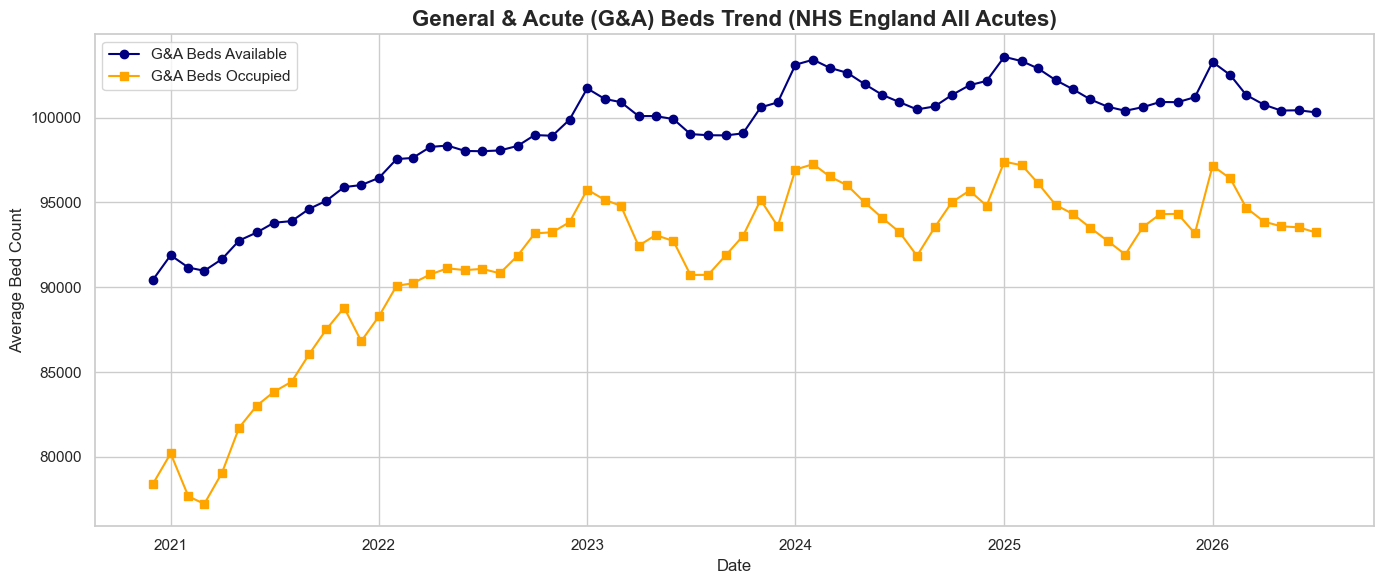

In [6]:
# Convert Month to datetime for plotting
df_all_acutes['Date'] = pd.to_datetime(df_all_acutes['Month'], format='%B %Y')
df_all_acutes = df_all_acutes.sort_values('Date')

# Plot General & Acute Beds
plt.figure(figsize=(14, 6))
plt.plot(df_all_acutes['Date'], df_all_acutes['G&A beds available'], label='G&A Beds Available', marker='o', color='navy')
plt.plot(df_all_acutes['Date'], df_all_acutes['G&A beds occupied'], label='G&A Beds Occupied', marker='s', color='orange')
plt.title('General & Acute (G&A) Beds Trend (NHS England All Acutes)', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Average Bed Count')
plt.legend()
plt.tight_layout()
plt.show()

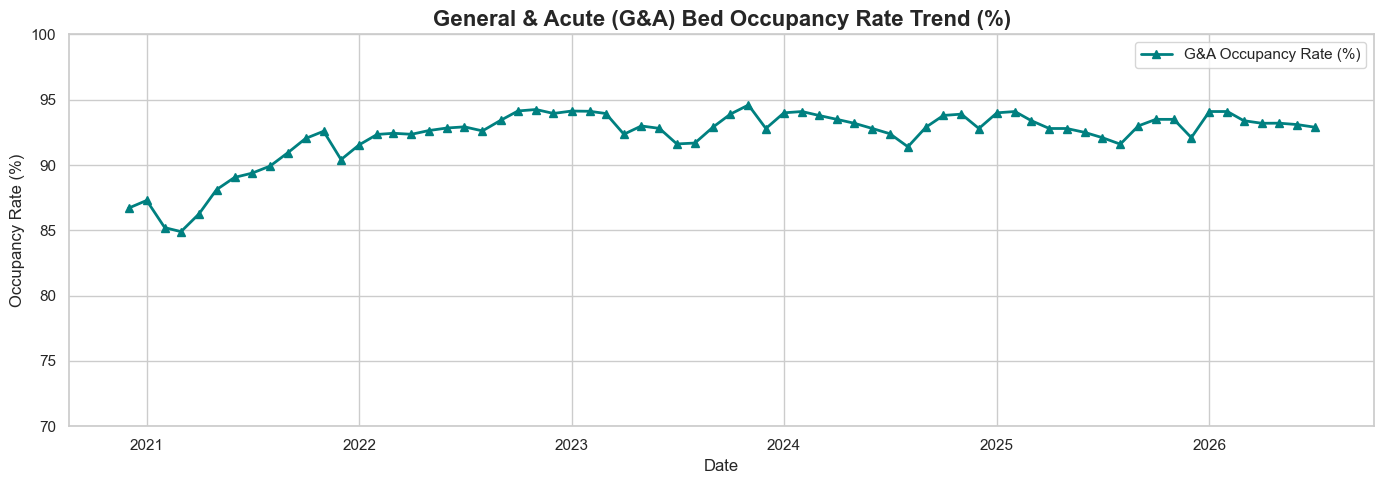

In [7]:
# Plot G&A Occupancy Rate
plt.figure(figsize=(14, 5))
plt.plot(df_all_acutes['Date'], df_all_acutes['G&A occupancy rate'] * 100, label='G&A Occupancy Rate (%)', marker='^', color='teal', linewidth=2)
plt.title('General & Acute (G&A) Bed Occupancy Rate Trend (%)', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Occupancy Rate (%)')
plt.ylim(70, 100)
plt.legend()
plt.tight_layout()
plt.show()

### 1.5 Critical Care (ICU) Beds Trends
We also plot the monthly trend for Adult Critical Care available vs occupied beds.

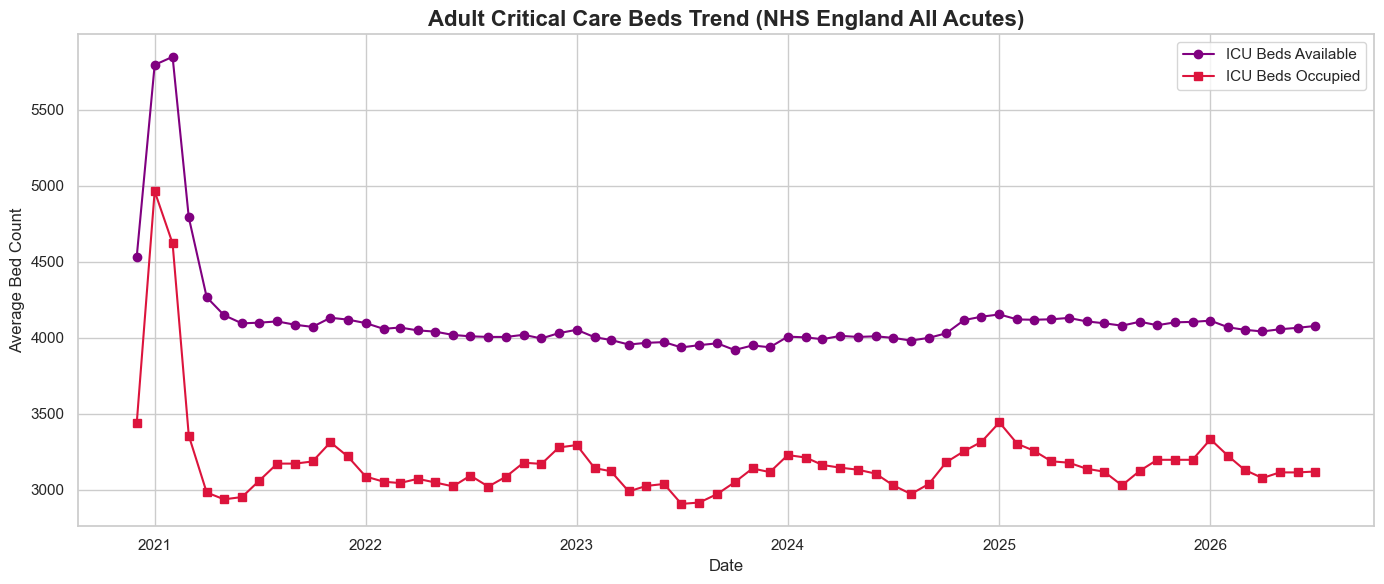

In [8]:
plt.figure(figsize=(14, 6))
plt.plot(df_all_acutes['Date'], df_all_acutes['Adult critical care beds available'], label='ICU Beds Available', marker='o', color='purple')
plt.plot(df_all_acutes['Date'], df_all_acutes['Adult critical care beds occupied'], label='ICU Beds Occupied', marker='s', color='crimson')
plt.title('Adult Critical Care Beds Trend (NHS England All Acutes)', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Average Bed Count')
plt.legend()
plt.tight_layout()
plt.show()

## 2. ICU Daily Demand Dataset
This dataset is derived by aggregating the MIMIC-IV clinical demo `icustays.csv.gz` table. It counts the daily number of occupied ICU beds.

In [9]:
icu_path = os.path.join(DATA_DIR, 'icu_daily_demand.csv')
df_icu = pd.read_csv(icu_path)
df_icu['date'] = pd.to_datetime(df_icu['date'])
print('ICU Daily Demand Shape:', df_icu.shape)
print('\nColumns and Data Types:')
print(df_icu.dtypes)
print('\nMissing values:', df_icu.isnull().sum())
print('Duplicates:', df_icu.duplicated().sum())
df_icu.head(10)

ICU Daily Demand Shape: (627, 2)

Columns and Data Types:
date             datetime64[ns]
occupied_beds             int64
dtype: object

Missing values: date             0
occupied_beds    0
dtype: int64
Duplicates: 0


,date,occupied_beds
0,2110-04-11,1
1,2110-04-12,1
2,2110-11-30,1
3,2110-12-01,1
4,2110-12-02,1
5,2110-12-03,1
6,2110-12-04,1
7,2110-12-05,1
8,2111-01-17,1
9,2111-01-18,1


### 2.1 Distribution and Sparsity Analysis
Because this dataset is derived from a limited 100-patient demo subset, the observations are highly sparse, spanning a massive date range of over 90 years. We show the descriptive stats and distribution of daily bed occupancy.

                                date  occupied_beds
count                            627     627.000000
mean   2149-06-20 17:11:11.770335232       1.009569
min              2110-04-11 00:00:00       1.000000
25%              2133-12-25 12:00:00       1.000000
50%              2146-07-07 00:00:00       1.000000
75%              2169-01-18 12:00:00       1.000000
max              2201-12-13 00:00:00       2.000000
std                              NaN       0.097432


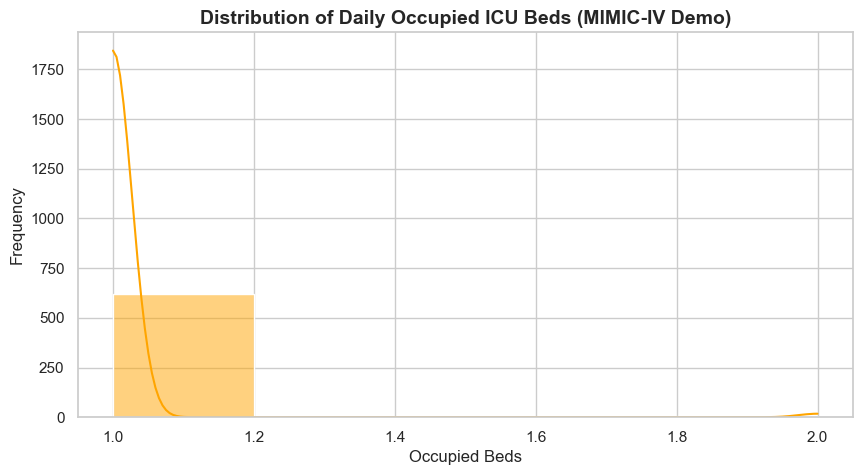

In [10]:
print(df_icu.describe())

# Histogram of occupied beds
plt.figure(figsize=(10, 5))
sns.histplot(df_icu['occupied_beds'], kde=True, bins=5, color='orange')
plt.title('Distribution of Daily Occupied ICU Beds (MIMIC-IV Demo)', fontsize=14, fontweight='bold')
plt.xlabel('Occupied Beds')
plt.ylabel('Frequency')
plt.show()

### 2.2 Time-Series Plot of ICU Occupancy
Since the observations are sparse and split across nearly a century, plotting them chronologically reveals large gaps of time with zero or single active stays. We plot a subset of the time-series where patients overlap.

Top 5 densest months in the dataset:
year_month
2135-01    21
2137-08    19
2150-03    19
2116-12    16
2156-04    15
Freq: M, Name: count, dtype: int64


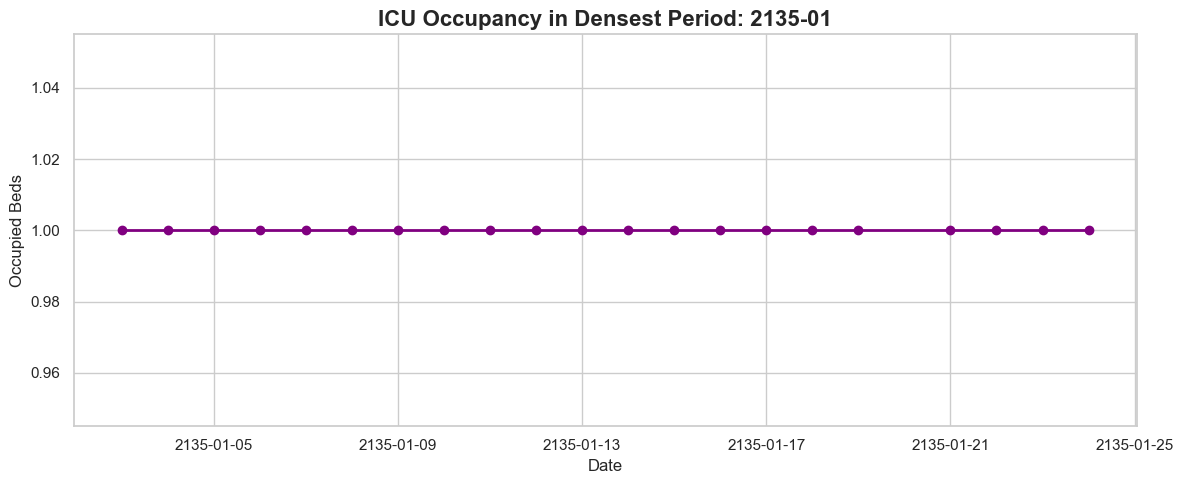

In [11]:
# Find a period with a cluster of events
df_icu_sorted = df_icu.sort_values('date')
# Get top 5 dense months
df_icu_sorted['year_month'] = df_icu_sorted['date'].dt.to_period('M')
dense_months = df_icu_sorted['year_month'].value_counts().head(5)
print('Top 5 densest months in the dataset:')
print(dense_months)

# Plot the densest month
if not dense_months.empty:
    best_month = dense_months.index[0]
    df_subset = df_icu_sorted[df_icu_sorted['year_month'] == best_month]
    plt.figure(figsize=(12, 5))
    plt.step(df_subset['date'], df_subset['occupied_beds'], where='mid', marker='o', color='purple', linewidth=2)
    plt.title(f'ICU Occupancy in Densest Period: {best_month}', fontsize=16, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Occupied Beds')
    plt.tight_layout()
    plt.show()
else:
    print('No overlapping periods found.')

## 3. Emergency Department (ED) Daily Demand
This dataset is derived from the MIMIC-IV-ED demo `edstays.csv.gz` table. It counts the number of emergency department arrivals per day.

In [12]:
ed_path = os.path.join(DATA_DIR, 'ed_daily_demand.csv')
df_ed = pd.read_csv(ed_path)
df_ed['date'] = pd.to_datetime(df_ed['date'])
print('ED Daily Arrivals Shape:', df_ed.shape)
print('\nColumns and Data Types:')
print(df_ed.dtypes)
print('\nMissing values:', df_ed.isnull().sum())
print('Duplicates:', df_ed.duplicated().sum())
df_ed.head(10)

ED Daily Arrivals Shape: (221, 2)

Columns and Data Types:
date        datetime64[ns]
arrivals             int64
dtype: object

Missing values: date        0
arrivals    0
dtype: int64
Duplicates: 0


,date,arrivals
0,2112-09-17,1
1,2113-12-13,1
2,2115-11-08,1
3,2116-02-27,1
4,2116-06-26,1
5,2116-12-02,1
6,2117-01-27,1
7,2117-03-14,1
8,2117-10-25,1
9,2119-10-26,1


### 3.1 Distribution and Sparsity Analysis

                                date    arrivals
count                            221  221.000000
mean   2157-10-17 22:15:44.796380160    1.004525
min              2112-09-17 00:00:00    1.000000
25%              2142-05-16 00:00:00    1.000000
50%              2150-04-09 00:00:00    1.000000
75%              2177-12-21 00:00:00    1.000000
max              2201-10-30 00:00:00    2.000000
std                              NaN    0.067267


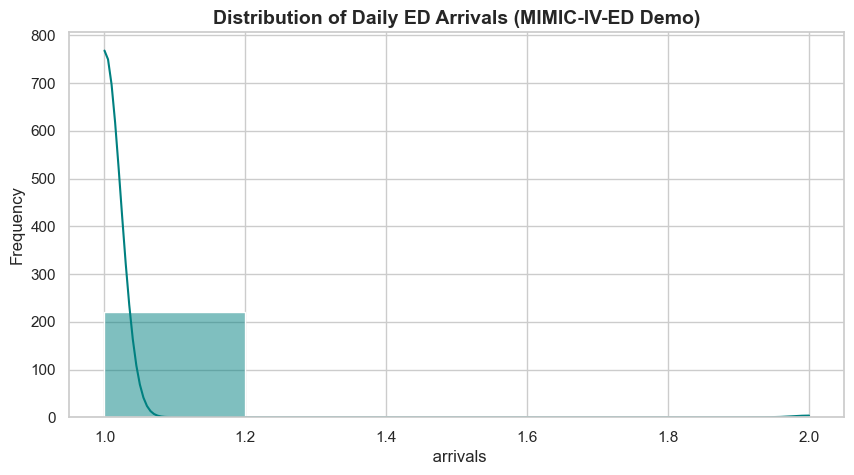

In [13]:
print(df_ed.describe())

# Histogram of ED arrivals
plt.figure(figsize=(10, 5))
sns.histplot(df_ed['arrivals'], kde=True, bins=5, color='teal')
plt.title('Distribution of Daily ED Arrivals (MIMIC-IV-ED Demo)', fontsize=14, fontweight='bold')
plt.xlabel(' arrivals')
plt.ylabel('Frequency')
plt.show()

### 3.2 Time-Series Plot of ED Arrivals
Similarly, we plot a subset of the ED arrivals time series during a relatively active period.

Top 5 densest months for ED arrivals:
year_month
2149-09    5
2147-12    4
2178-07    4
2147-11    3
2151-01    3
Freq: M, Name: count, dtype: int64


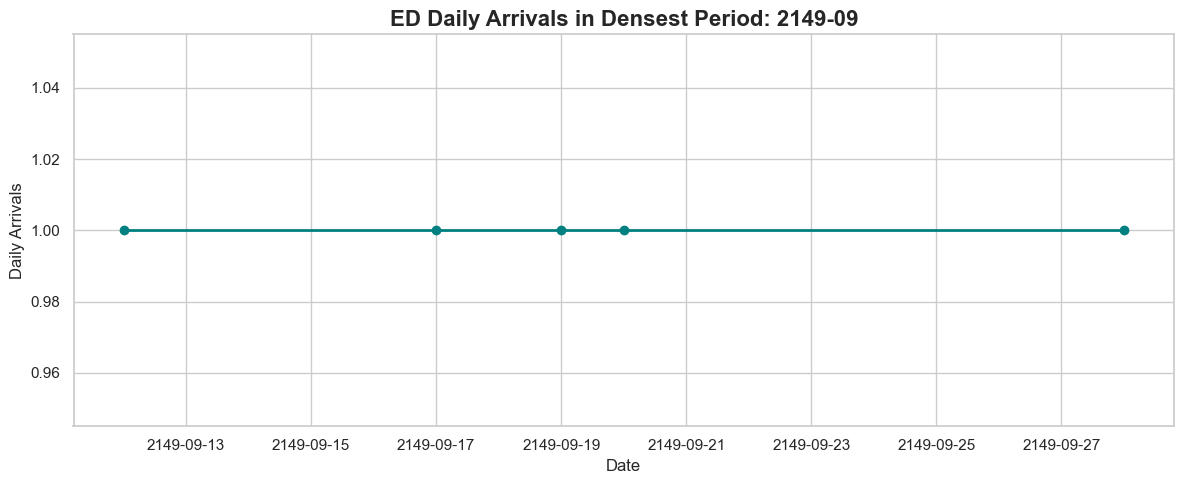

In [14]:
df_ed_sorted = df_ed.sort_values('date')
df_ed_sorted['year_month'] = df_ed_sorted['date'].dt.to_period('M')
ed_dense_months = df_ed_sorted['year_month'].value_counts().head(5)
print('Top 5 densest months for ED arrivals:')
print(ed_dense_months)

if not ed_dense_months.empty:
    best_month_ed = ed_dense_months.index[0]
    df_subset_ed = df_ed_sorted[df_ed_sorted['year_month'] == best_month_ed]
    plt.figure(figsize=(12, 5))
    plt.step(df_subset_ed['date'], df_subset_ed['arrivals'], where='mid', marker='o', color='teal', linewidth=2)
    plt.title(f'ED Daily Arrivals in Densest Period: {best_month_ed}', fontsize=16, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Daily Arrivals')
    plt.tight_layout()
    plt.show()

## 4. Key Limitations & Findings for Forecasting
1. **NHS Beds Dataset**:
   - **Structure**: Monthly time-series data.
   - **Date Range**: March/December 2020 - July 2026 (76 to 85 observations).
   - **Limitation**: The monthly frequency makes it impossible to do daily (7-day) forecasting. It can only be used for monthly forecasting or historical capacity baseline analysis.
   - **Features**: Highly complete, includes General & Acute and Critical Care (ICU) beds availability, core beds, escalation beds, occupied beds, and occupancy rates.

2. **ICU Daily Demand (MIMIC-IV Clinical Demo)**:
   - **Structure**: Daily active stays.
   - **Limitation**: Highly sparse (140 observations total, spread over 91 years). Most days in this 91-year range have 0 active patients because of the small sample size (100 patients).
   - **Feasibility**: For time-series models like Prophet or LSTM, chronological continuity is required. Splitting this data or training models on a century-long, extremely sparse dataset will lead to poor forecasting. For a B.Tech project presentation, we will need to document this sparsity and recommend a strategy (e.g., focus on the dense subset or shift dates to form a synthetic dense series for demo purposes, or note it as a critical data gap).

3. **ED Daily Demand (MIMIC-IV-ED Demo)**:
   - **Structure**: Daily arrivals.
   - **Limitation**: Similarly sparse (222 arrivals spread over 89 years).

### Final Recommendation for the Project Target
- **Primary forecasting target**: Since our project focuses on forecasting hospital resource demand, we will use the NHS beds dataset for a **Monthly Forecast** (e.g. forecast the next month) OR we can use a **shifted, densified version** of the ICU/ED daily stays to simulate daily time-series forecasting. We will discuss this with the advisor (or decide during Stage 2 Preprocessing).